# Identification
Please indicate your name and parcours (e.g.: IMA, DIGIT, BIM, DAC, ..., Erasmus)

Student 1: 

Student 2: Daria SHTYKA (MIND)

# Practical work 3: 2D sampling and aliasing 

Properties studied in 1D apply in 2D. The following results can be admitted: 
 - given a regular grid, a sampling of a continuous 2D signal can be modeled as follows:
$$
x_s(t,u) = x(t,u)C(t,u)\quad \text{with}\quad C(t,u) = \sum_{k=-\infty}^{+\infty} \sum_{l=-\infty}^{+\infty} \delta(t-kT_s,u - lT_s)
$$ $C$ is the analog of Dirac comb (also called impulse train) in 2D
 - spectrum of $x_s$ writes:
$$
X_s(f,g) = \frac1{T_s^2}\sum_{k=-\infty}^{+\infty} \sum_{l=-\infty}^{+\infty} X(f-kf_s,g-lf_s)
$$
2D sampling then implies a periodization of the spectrum for the two dimensions
 - it is possible to reconstruct the original signal from the sampled signal if the 2D Shannon condition is verified (band-limited signal) with:
$$
x_r (t,u) = \sum_{k=-\infty}^{+\infty} \sum_{l=\infty}^{+\infty} x_s(kT_s,lT_s) \operatorname{sinc}(\pi f_s (t-kT_s)) \operatorname{sinc}(\pi f_s(u - lT_s))\qquad\qquad\qquad\text{(1)}
$$
so-called Shannon interpolation.
 
## Exercise 1: aliasing and windowing of 2D signals
 
Given the following signal:
$$
s_\theta(t,u) = A\cos(2\pi f_0(t\cos\theta + u\sin\theta))
$$
Here an example with $\theta=\frac\pi4$:
<div><img src="attachment:sinus2d.png" width=200></div>
The goal of this exercise is to study the limit conditions of sampling this image in order to avoid aliasing.

In [2]:
import numpy as np
from numpy.fft import fft2, fftshift
import matplotlib.pyplot as plt
# for interactive ploting, see surf() below
# %matplotlib notebook
%matplotlib inline
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D

def sinusoid2d(A, theta, size, T0, Te):
    """ double**2*int*double**2 -> Array[double] """
    ct = np.cos(theta/180*np.pi)
    st = np.sin(theta/180*np.pi)
    x, y = np.meshgrid(np.arange(0, size, Te), np.arange(0, size, Te))
    return A*np.cos(2*np.pi*(y*ct - x*st)/T0)

def shannonInterpolation(I, Ts, size):
    """ Array*int*double -> Array[double] """
    n, m = I.shape
    x, y = np.meshgrid(np.arange(0, size), np.arange(0, n))
    Y = np.sinc(x/Ts-y)
    x, y = np.meshgrid(np.arange(0, size), np.arange(0, m))
    X = np.sinc(x/Ts-y)
    return np.matmul(X.T, np.matmul(I, Y))

def imshow_c(I,title=None):
    """ display an image """
    plt.figure(figsize=(500//80,500//80))
    plt.gray()
    plt.imshow(I)
    if title: plt.title(title)
    plt.show()

def surf(Z,title=None):
    """ 3D plot of an image """
    X,Y = np.meshgrid(range(Z.shape[1]), range(Z.shape[0]))
    fig = plt.figure(figsize=(600/80,600/80))
    if title: plt.title(title)
    # ax = fig.gca(projection='3d')
    ax = plt.subplot(projection='3d')
    ax.plot_surface(X, Y, Z, cmap=cm.coolwarm, linewidth=0, antialiased=False)
    plt.show()
    

    

1. We provide the function `sinusoid2d(A, theta, L, T0, Ts)` that allows sampling signal $s_\theta$ with a sampling period of `Ts` (the grid is regular with the sample sampling value for directions $u$ and $t$). Parameters `A`, `theta`, `L`, and `T0` respectively control the amplitude, orientation, and period ($T_0=\frac1{f_0}$) of signal $s_\theta$. Generate a pseudo continuous signal $s_{45}$ with `A=1`, `theta = 45`, `L = 512`, `T0 = 64` and `Ts=1`.


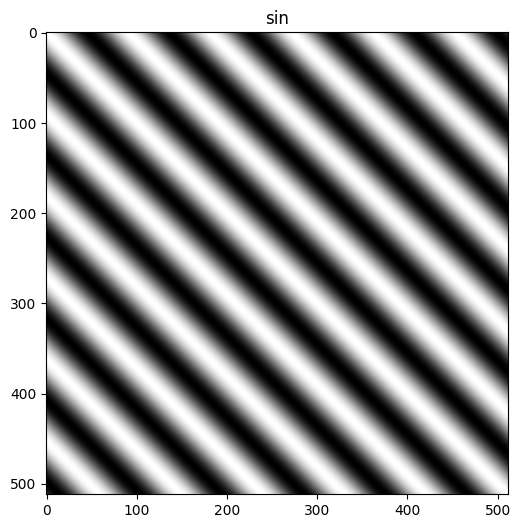

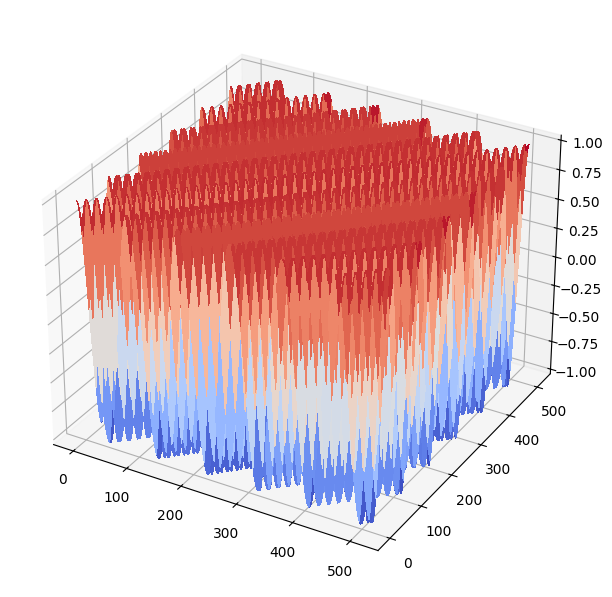

In [3]:
s45 = sinusoid2d(1, 45, 512, 64, 1 )
imshow_c(s45, "sin")
surf(s45)
# plt.imshow(s45)
# print(s45)

2. (a) What is the maximal frequency of previous signal $s_{45}$ in direction $t$ (denoted $f_t^{\text{max}}$) and direction $u$ (denoted $f_u^{\text{max}}$)? Let $f_m = \max(f_t^{\text{max}},f_u^{\text{max}})$. Explain why $f_m$ can be used to derive the limit frequency (in sens of Shannon) for the sampling of $s_{45}$.

\begin{align*}
    s_\theta(t,u) &= A\cos(2\pi f_0(t\cos\theta + u\sin\theta)) \\
        &= A\cos(2\pi (f_0 t\cos\theta + f_0 u\sin\theta)) \\
\end{align*}

So $f_t^{\text{max}}$= $ f_0 \cos \theta $ and  $f_u^{\text{max}}$ = $ f_0 \sin \theta $

It can be used to derive the limit frequency beacause according to shannon  $f_s$ >= 2 $f_{\text{max}}$ so here $f_s$ >= 2 $f_0$

In our case $ \theta = \frac{\pi }{4} \Leftrightarrow \cos \theta = \sin \theta = \frac{\sqrt[]{2}}{2} $  so 
$$
    f_m = \max (f_t^{max}, f_u^{max}) = \max (\frac{1}{64}* \frac{\sqrt[]{2}}{2}, \frac{1}{64}* \frac{\sqrt[]{2}}{2}) = \frac{1}{64}* \frac{\sqrt[]{2}}{2} = \frac{\sqrt[]{2}}{128}
$$
Then according to the theorem of Shannon, we have
$$
f_s \geq 2f_m \Leftrightarrow f_s \geq \frac{\sqrt[]{2}}{64}
$$

2. (b)  Sample $s_{45}$ with $f_s = 16 f_m$ and display the sampled signal.

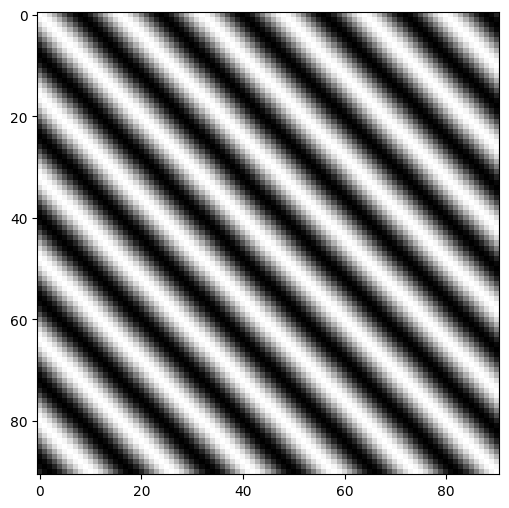

In [4]:
fm = np.sqrt(2) / 128
fs = 16 * fm
Ts = 1 / fs

s45_sampled = sinusoid2d(1, 45, 512, 64, Ts)
imshow_c(s45_sampled)

# s45_sampled = shannonInterpolation(s45,Ts, 512) #FAUX
# imshow_c(s45_sampled)

2. (c) Compute the Fourier transform of the sampled signal and display frequencies. One can use `surf()` function for an interactive 3D plot.

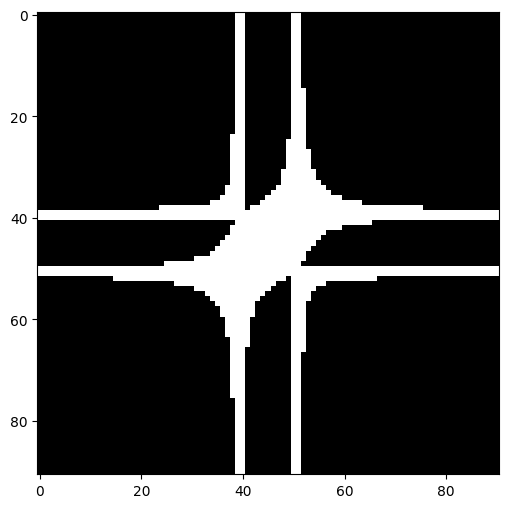

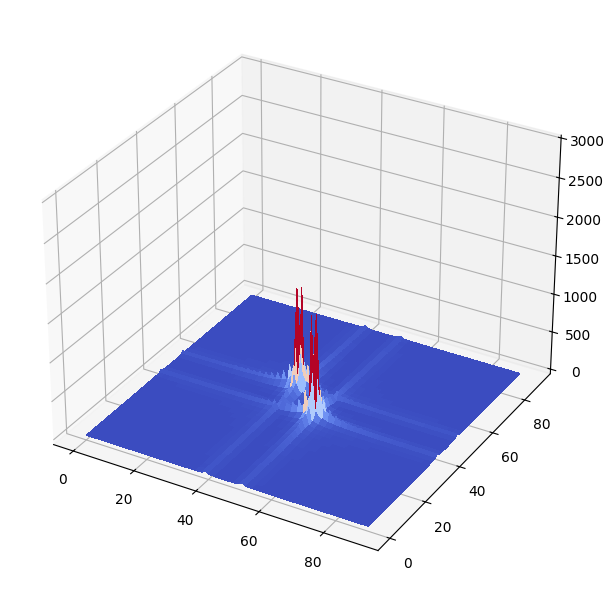

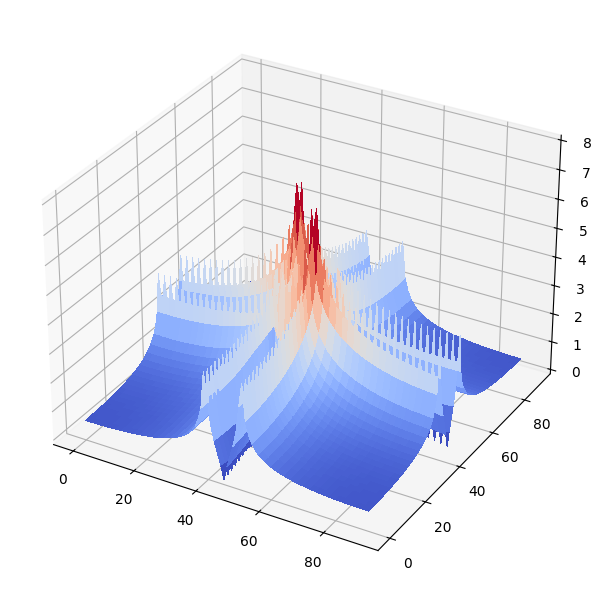

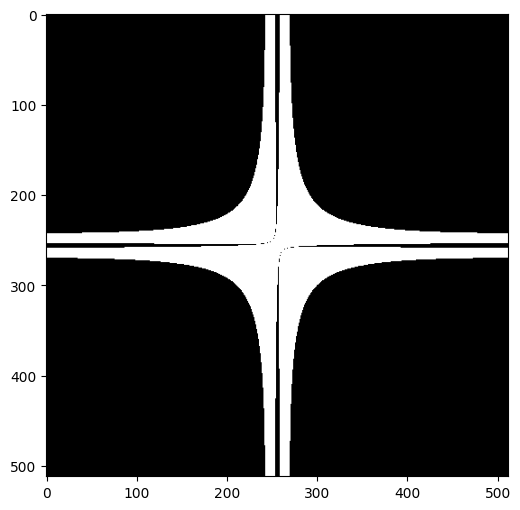

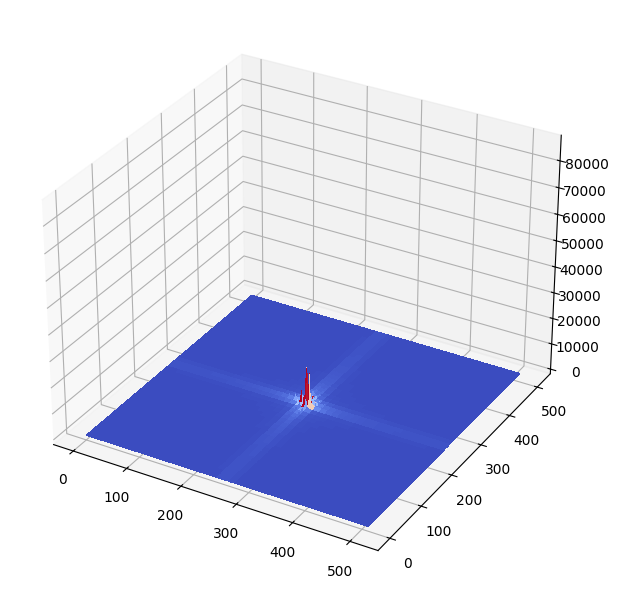

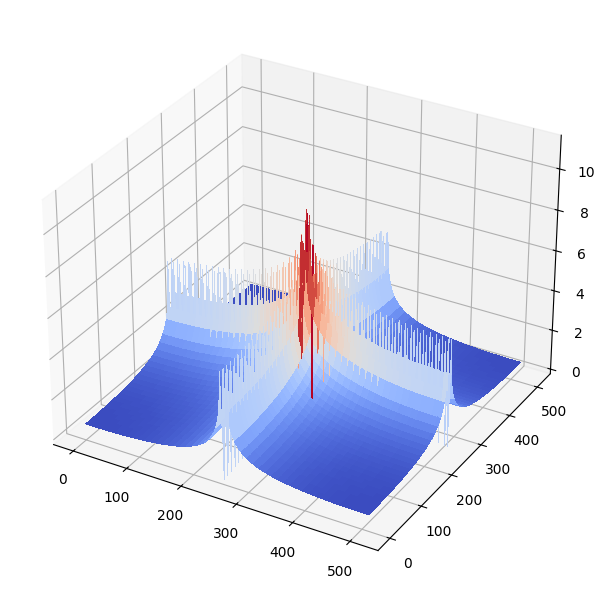

In [5]:
#sampled signal
ss45_FT = fft2(s45_sampled)
ss45_FT_VIS = np.abs(fftshift(ss45_FT))
ss45_FT_log = np.log(1+ss45_FT_VIS)
imshow_c(ss45_FT_VIS>(11.10 ))
# plt.hist(s4)
surf(ss45_FT_VIS)
surf(ss45_FT_log)

# coninuous signal
s45_FT = fft2(s45)
s45_FT_VIS = np.abs(fftshift(s45_FT))
s45_FT_log = np.log(1+s45_FT_VIS)
imshow_c(s45_FT_VIS>(11.10 ))
# plt.hist(s4)
surf(s45_FT_VIS)
surf(s45_FT_log)

2. (d) Comment the spectrum:
    - verify the presence of the two Dirac peaks
    - for various values of $T_s$, observe changes in the spectrum. Compare with the spectrum of the continuous signal ($s_{45}$). What is the origin of these differences?
    - Why, aside from the two Dirac peaks, there are some structures? Explain the origin of these lobes.
    - Increase $T_0$ in order to obtain a unique peak. Explain the origin of this fusion. Verify the limit value of $T_0$ for which the two peaks interfere.

- les deux piques sont présentes
- le spectre continue a plutot une pique tandis que le spectre échantilloné en a 2. L'origine de cette différence est dans la fonction qui fait que le signal échantilloné est délimité entre -1/T et 1/T en effectuant une convolution et dans le spectre continue c'était une multiplication avec temps comme résultat T. Pour la valeur Ts, le plus on diminue Ts (<=>car on augmente fmax), le plus l'image est proche à celui d'origine. Concernant les piques de FFT, elles se rapprochent en diminuant Ts puisque fs devient de plus en plus proche de fmax. Donc les piques commencent à se chevaucher.
- Il y'a d'autres lobes à part les piques puisque le signal soit fenêtré par deux fonctions $Rect$. Lors de la transformé de Fourier, ces deux fonctions se transforme en $sinc$, créant ainsi ces lobes.
- On augmente le facteur de T0 jusqu'à 100 on fait fusionner les 2 piques.

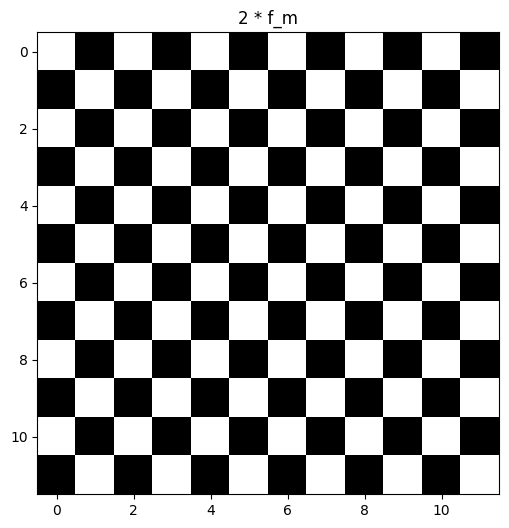

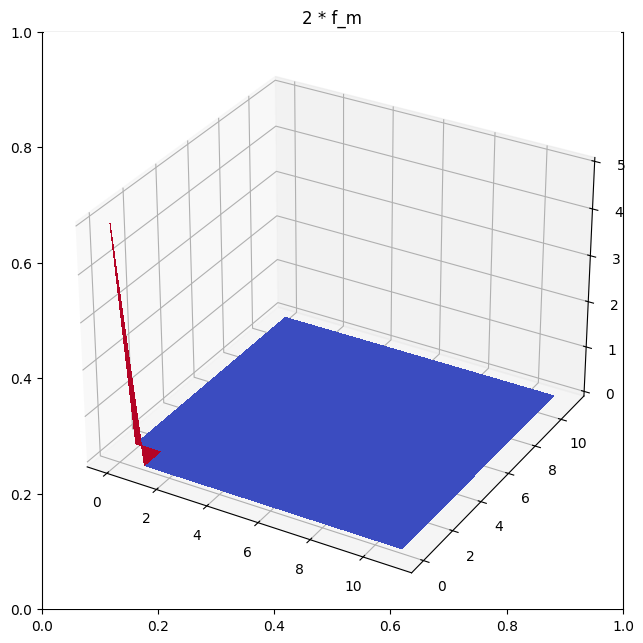

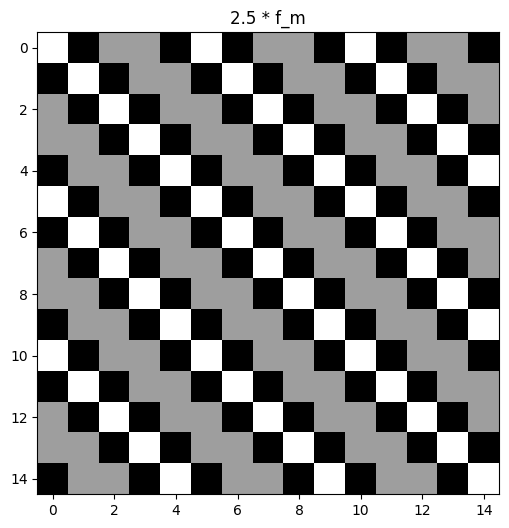

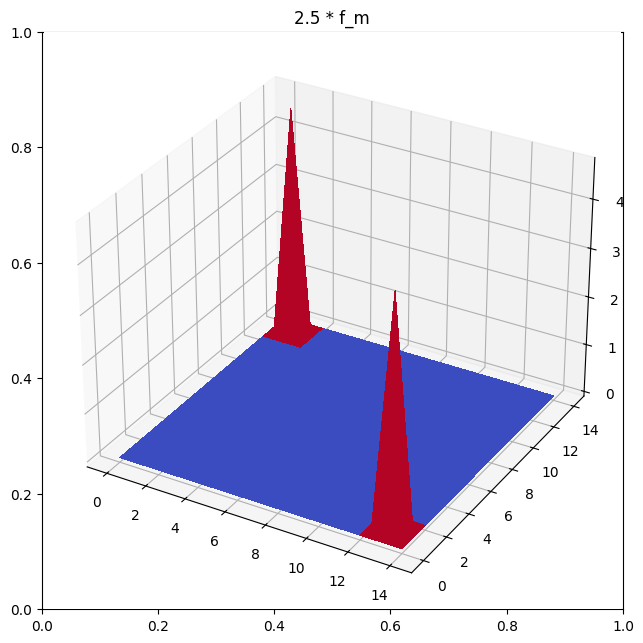

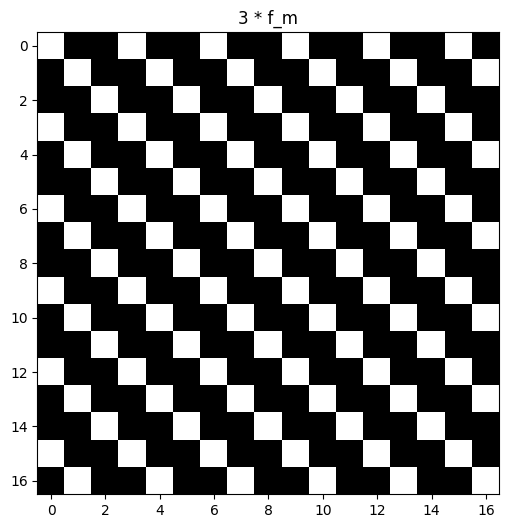

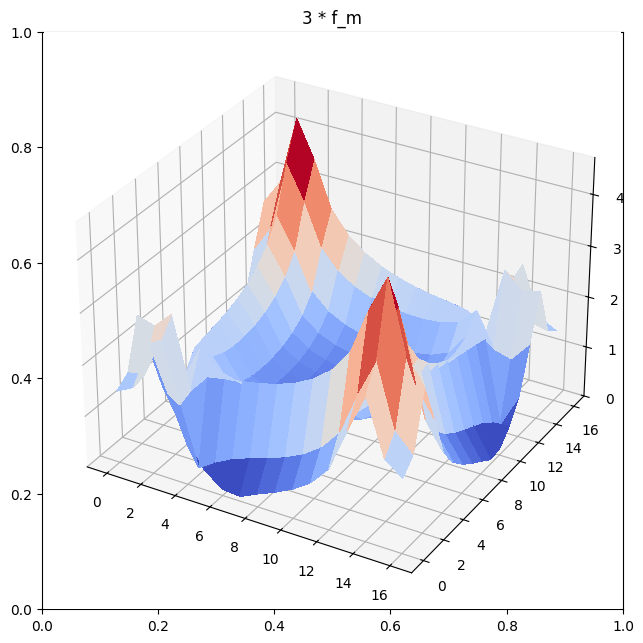

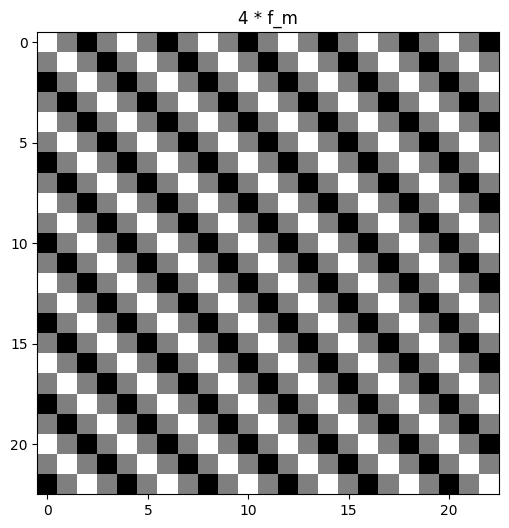

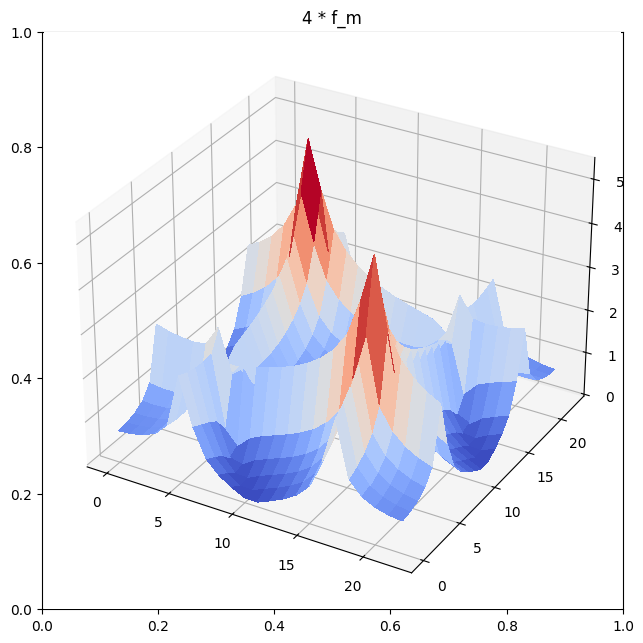

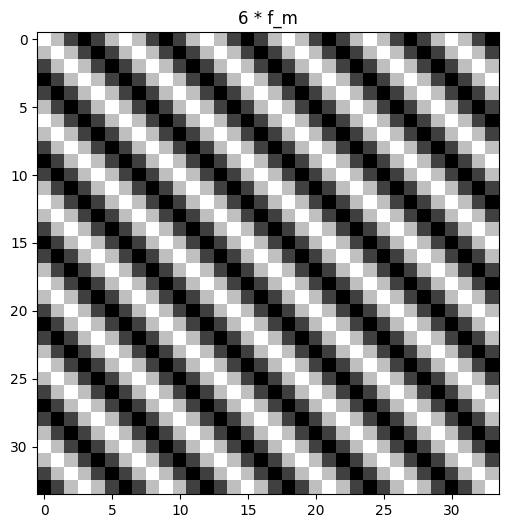

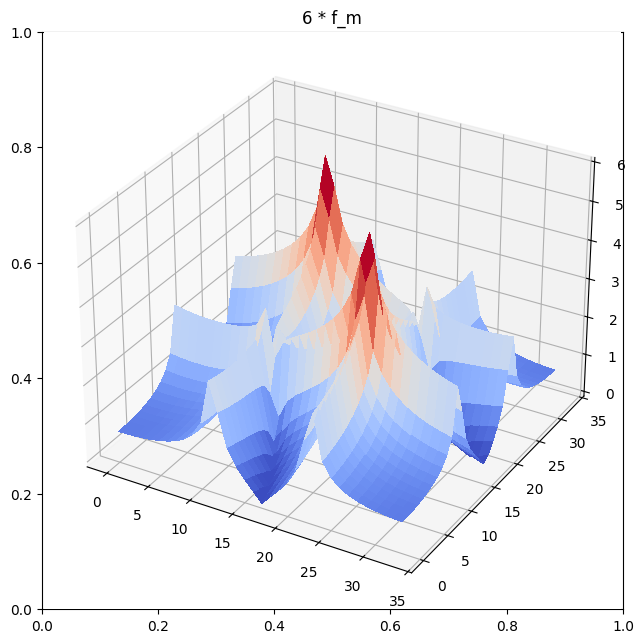

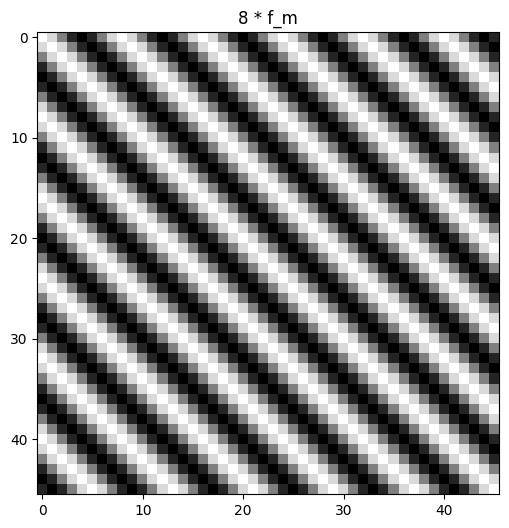

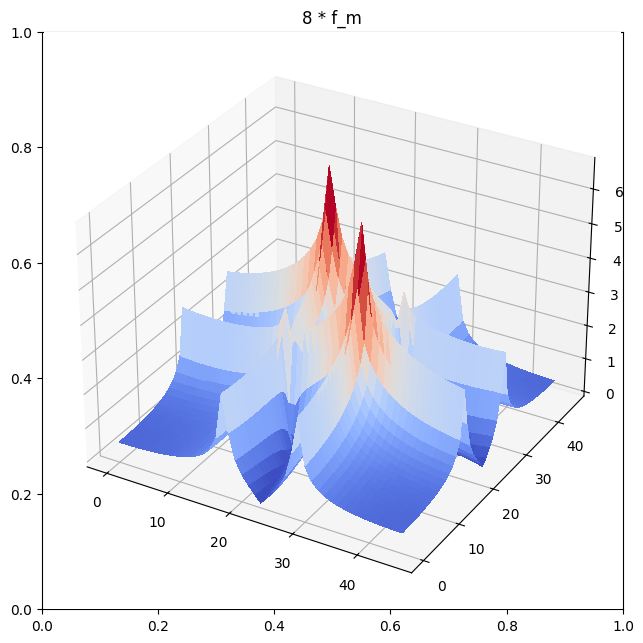

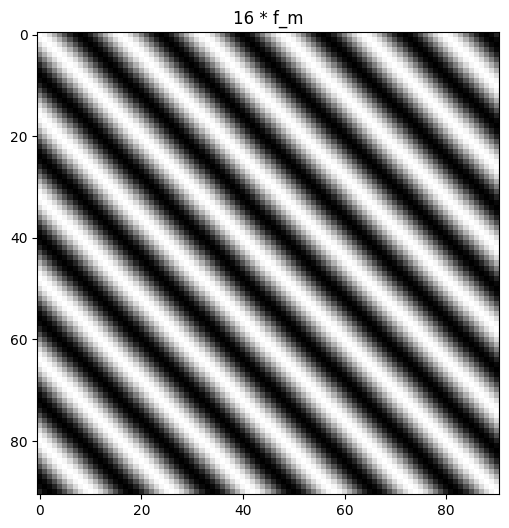

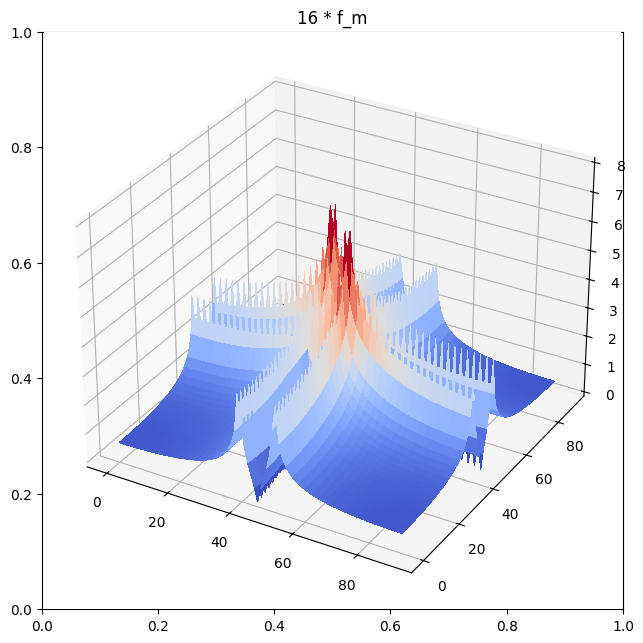

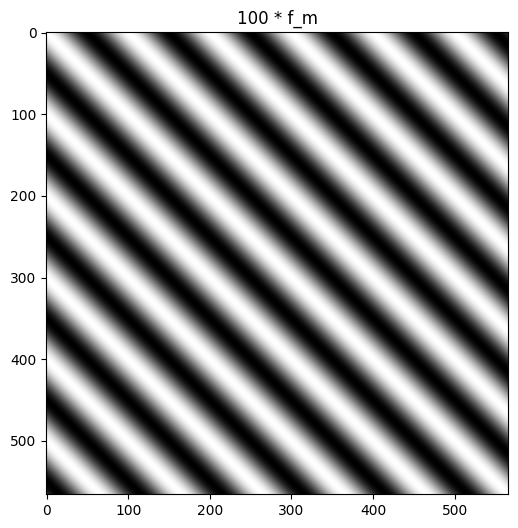

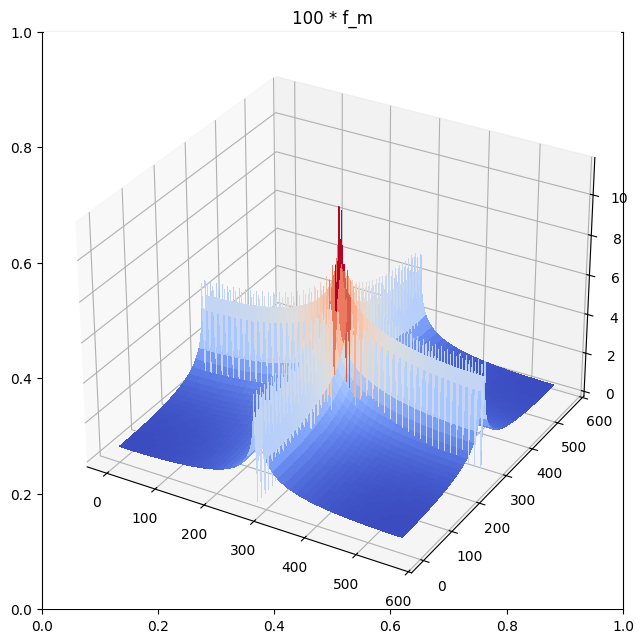

In [6]:

def f_max(T0, theta):
    return max(np.cos(theta/180*np.pi), np.sin(theta/180*np.pi))/T0

for factor in [2, 2.5, 3, 4, 6, 8, 16, 100]:
    # 100,16,8,6,4,3,2.5,2
    s45_s = sinusoid2d(A=1,theta=45, size=512, T0=64, Te= 1/f_max(64,45)/factor)
    ss45_FT = fft2(s45_s)
    ss45_FT_VIS = np.abs(fftshift(ss45_FT))
    ss45_FT_log = np.log(1+ss45_FT_VIS)
    imshow_c(s45_s, title=f"{factor} * f_m")
    surf(ss45_FT_log, title=f"{factor} * f_m")

3. (a) Sample $s_{45}$ with $f_s=4 f_m$ and display the sampled signal.

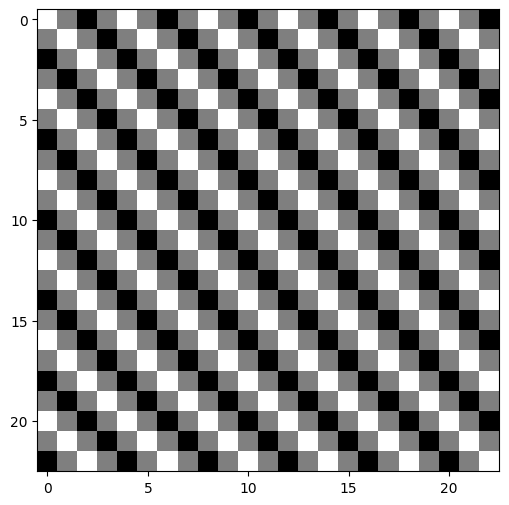

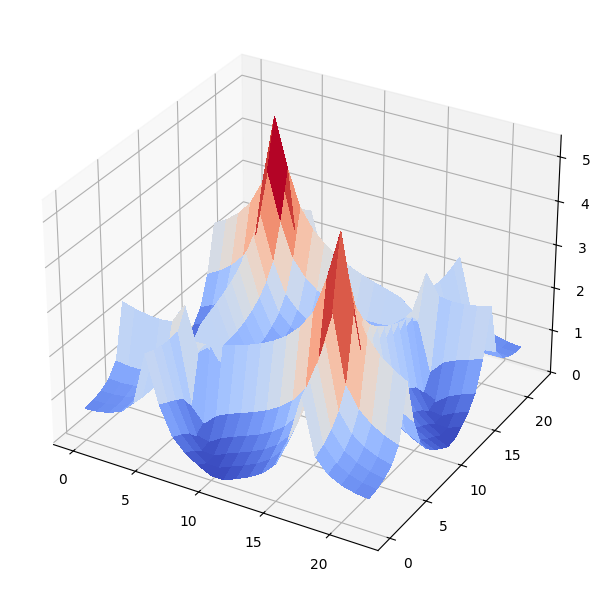

In [9]:
s45_s_4times_fm = sinusoid2d(A=1,theta=45, size=512, T0=64, Te= 1/(4*f_max(64,45)))
s45_FT4 = fft2(s45_s_4times_fm)
s45_FT4_VIS = np.abs(fftshift(s45_FT4))
s45_FT4_log = np.log(1+s45_FT4_VIS)
imshow_c(s45_s_4times_fm)
# plt.hist(s4)
# surf(s45_FT4_VIS)
surf(s45_FT4_log)

3. (b) Write a function `error()` implementing the relative average error $\displaystyle\epsilon_r = \frac 1{2AL^2}\sum_{k=0}^L\sum_{l=0}^L |x_r(k,l)-x_d(k,l)|$.

In [11]:
def error(signal, reconstructed_signal, A=1, L=512):
    s =0
    for k in range(L):
        for l in range(L):
            s += np.abs(reconstructed_signal[k,l] - signal[k,l])
    return 1/(2*A*L**2) * s

3. (c) Reconstruct the sampled signal. Display original and reconstructed signal.
   Print the relative average error between the original and reconstructed images. What is the origin of this error?

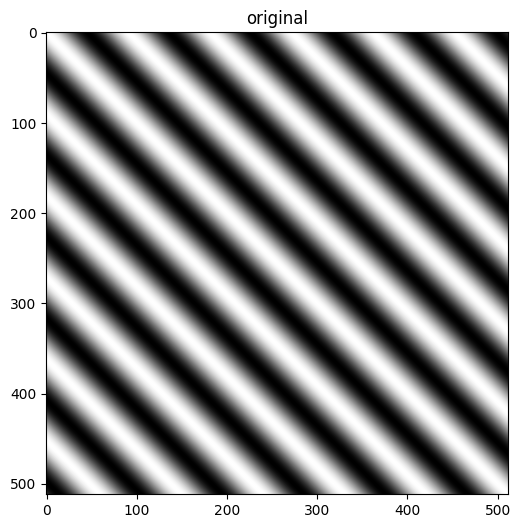

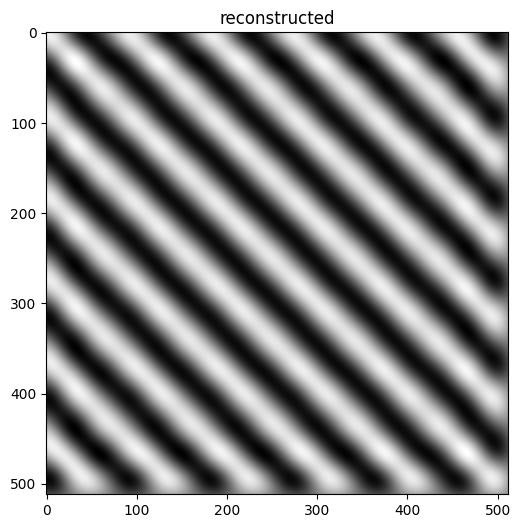

0.022936924363102643


In [ ]:
s_reconstructed = shannonInterpolation(s45_s_4times_fm, 1/(4*f_max(64,45)), 512)
imshow_c(s45, "original")
imshow_c(s_reconstructed, "reconstructed")
print(error(s45, s_reconstructed))

#L'origine de la faute est l'alising: Bien que nous respectons la condition de Shannon, quand on échantillonne les frequences très hautes (notamment les contours) deviennent indiscernables des basses fréquences et donc on l'observe dans la reconsctruction.

4. Same question than 3. with $f_s = \frac32f_m$. Comment the effects of aliasing.

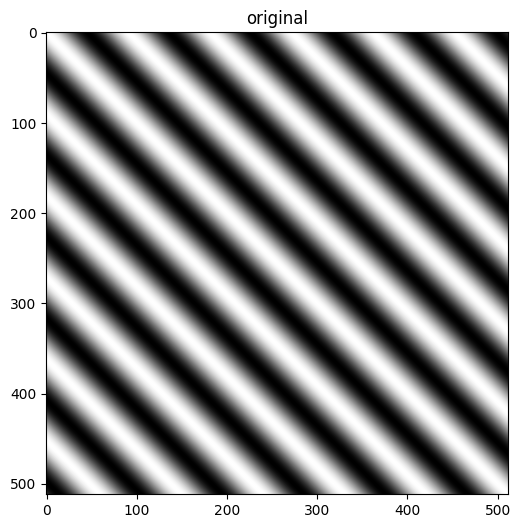

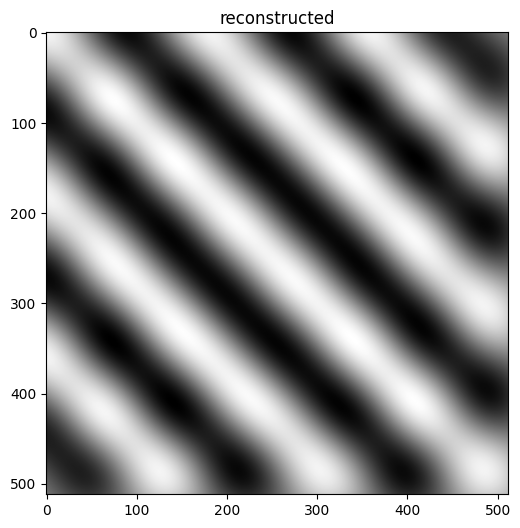

0.4068626475014679


In [21]:
s45_s_32times_fm = sinusoid2d(A=1,theta=45, size=512, T0=64, Te= 1/((3/2)*f_max(64,45)))
s32_reconstructed = shannonInterpolation(s45_s_32times_fm, 1/((3/2)*f_max(64,45)), 512)
imshow_c(s45, "original")
imshow_c(s32_reconstructed, "reconstructed")
print(error(s45, s32_reconstructed))
#L'image reconstruit a des erreurs puisque nous ne respectons pas la condition de Shannon et les sinus cardinaux se superposent.
# On doit repsecter fs<2fmax alors que fs=3/2fmax < 2fmax

5. Consider the continuous signal with an oriention of $\theta=10°$. What is the value of $f_m$? With a sampling of $\frac32 f_s$ what is the additional drawback appearing after the reconstruction? Explain.

0.01538762114081575


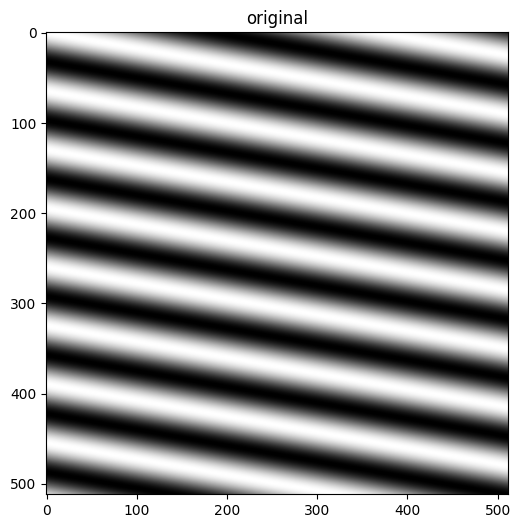

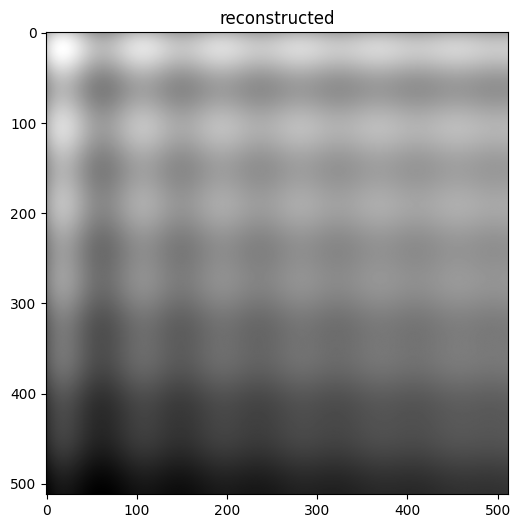

0.45076586291325565


In [ ]:

# s10_fm = sinusoid2d(A=1,theta=10, size=512, T0=64, Te= 1/((3/2)*f_max(64,10)))
fm_theta10 = f_max(64,10)
s10_fm = sinusoid2d(A=1,theta=10, size=512, T0=64, Te= 1)
print(fm_theta10)
# print(f_max(64,45))
s10_reconstructed = shannonInterpolation(s10_fm, 1/((3/2)*fm_theta10), 512)
imshow_c(s10_fm, "original")
imshow_c(s10_reconstructed, "reconstructed")
print(error(s10_fm, s10_reconstructed))

#L'erreur en plus est que nous avons dans l'image réconstruit des frequences dans des mauvaises directions

6. Write a function `shannonInterpolationLoop()` implementing equation (1) using four nested loops, in a C way. Compare and discuss the run time of this function and  `shannonInterpolation()` on a small signal ($L=64$). Runtime can be measured using `tic()` and `tac()` functions.

In [ ]:
from time import process_time
mytime = 0
def tic():
    """ NoneType -> NoneType """
    global mytime
    mytime = process_time()
def tac():
    """ NoneType -> int """
    global mytime
    print (process_time()-mytime)
    mytime = process_time()

### your code starts below
def shannonInterpolationLoop(I, Ts, size):
    n, m = I.shape
    fs = 1/Ts
    return np.array([[np.sum([np.sum([ I[k,l]*np.sinc(u*fs/(Ts - l))*np.sinc(t*fs/(Ts - k)) 
                                      for l in range(n)])
                                      for k in range(m)])
                                      for u in range(size)] 
                                      for t in range(size)])
f_m = np.sqrt(2)/128
T0 = 1/(4*f_m)
s = sinusoid2d(1, 45, 64, 64, 1)
s_sampled = sinusoid2d(1, 45, 64, 64, T0)

tic()
print("ShannonInterpolation w/ matmul")
r_signal = shannonInterpolation(s_sampled, T0, 512)
tac()

tic()
print("ShannonInterpolation w/ loop")
r_signal = shannonInterpolationLoop(s_sampled, T0, 512)
tac()

#loop prends beaucoup plus de temps que matmul car multiplicatin se fait en temps linéaire et loop en n^4


ShannonInterpolation w/ matmul
0.0014730000000007237
ShannonInterpolation w/ loop
13.656414999999999



## Exercise 2: aliasing on natural images

In this exercise, we study aliasing on image `img/barbara.png`. Aliasing occurring with subsample of image, we propose to write a code that implements a subsample (using function `subSample2()` of factor 2 on the image.  

1. Explain what is a subsample of factor 2 and the impact when applied on an image. 

C'est quand on garde seulement la moitié des pixels dans les deux directions (un sur deux). Cela reduit la taille de l'image de facteur 4 => on perd de l'information (= la frèquence) => on obitens les faux patterns => aliasing.

2. Write a code that
 - iterates the subsampling process
 - at each iteration, computes the Fourier transform of the subsampled image

   Display subsampled images and their spectrum. Describe and interpret the effects of aliasing. Why aliasing is a drawback ?

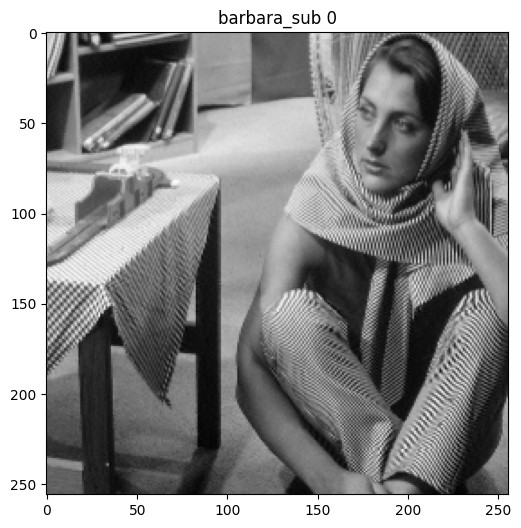

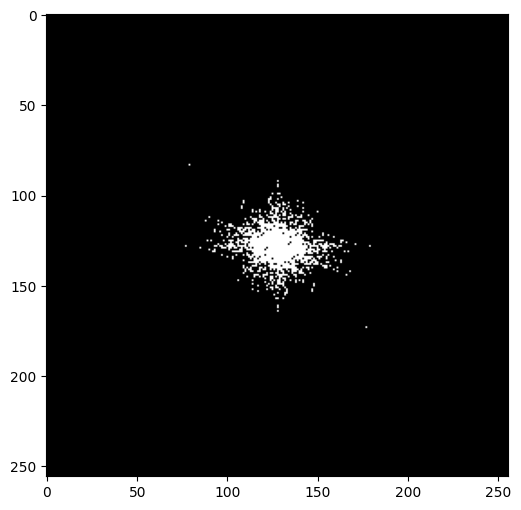

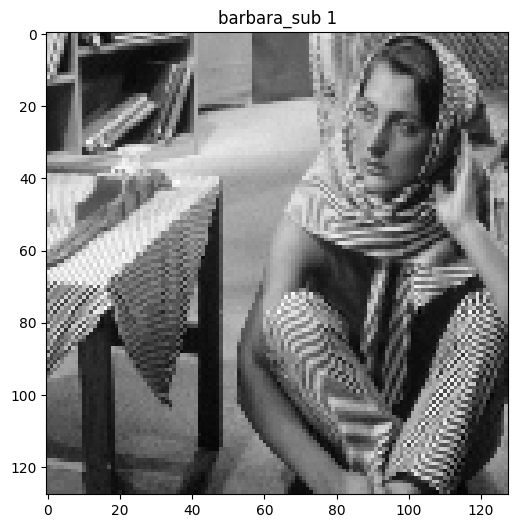

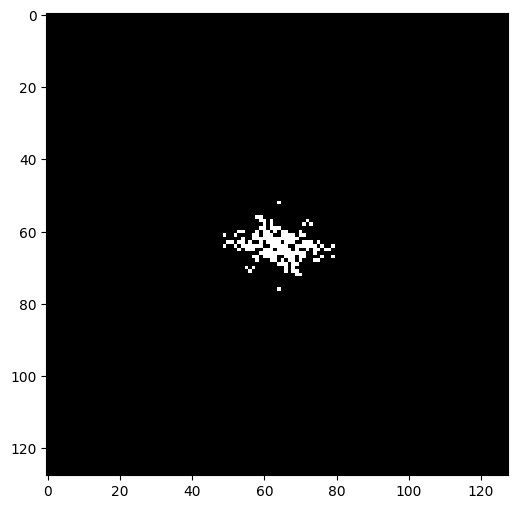

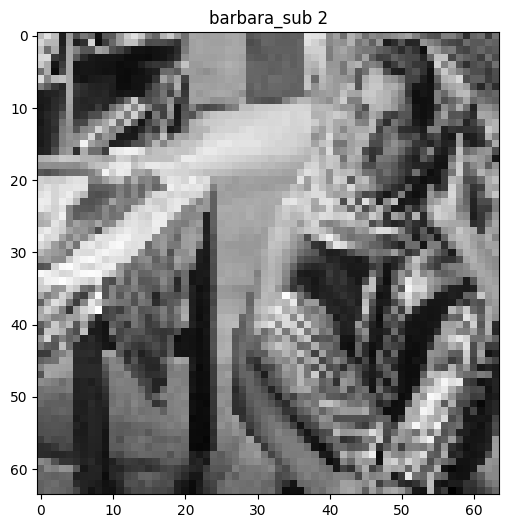

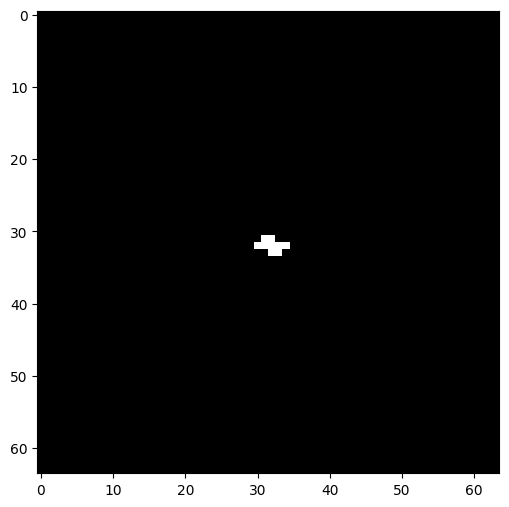

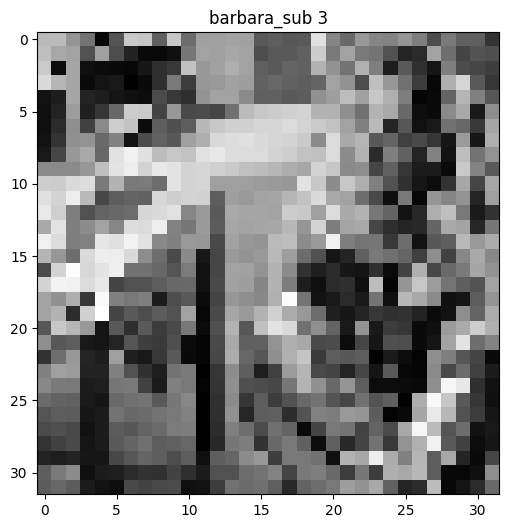

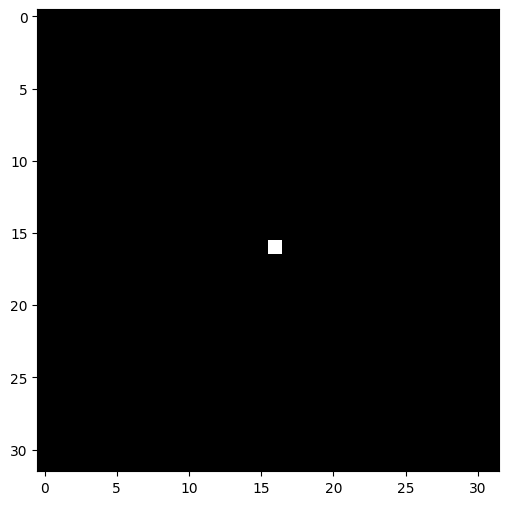

In [ ]:
from PIL import Image
def subSample2(I):
    # I_factored = [[I[i][j]for j in range(len(I[i]))] for i in range(len(I), 2)]
    return I[::2,::2]

barbara = np.array(Image.open('barbara.png'))

barbara_aliasing = barbara.copy()
for i in range(4):
    barbara_aliasing = subSample2(barbara_aliasing)
    imshow_c(barbara_aliasing, "barbara_sub "+str(i))
    b_fft = fft2(barbara_aliasing)
    b_fft_cent = np.abs(fftshift(b_fft)) 
    b_fft_log = np.log(1+b_fft_cent)
    # imshow_c(b_fft_log>11.10)
    imshow_c(b_fft_log>10.10)

#Plus on enleve les pixels plus les countours sont dispersées d'où la FT plus concetrée. L'aliasing est desavanatageux car nous ne voyons pas bien l'image au final.

3. Same question with the image `img/mandrill.png`.

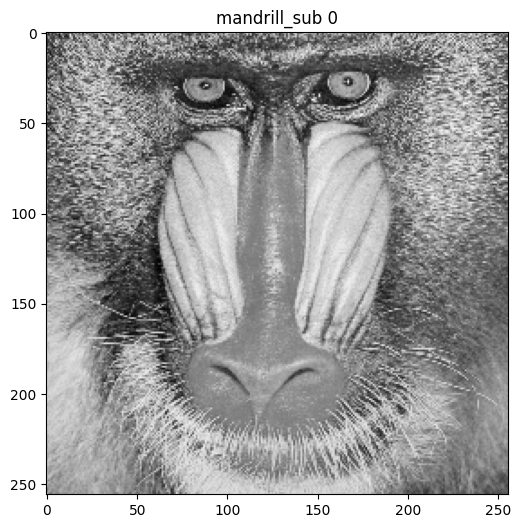

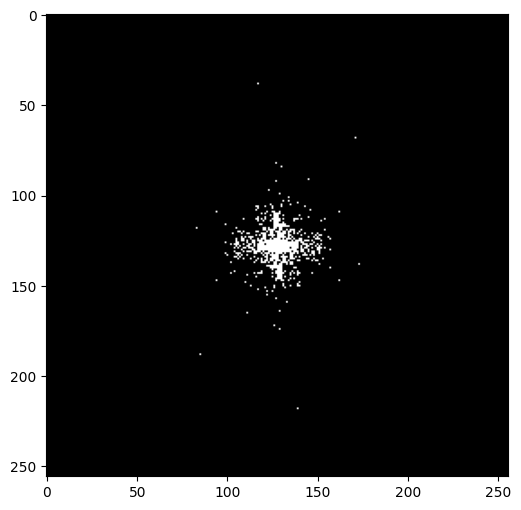

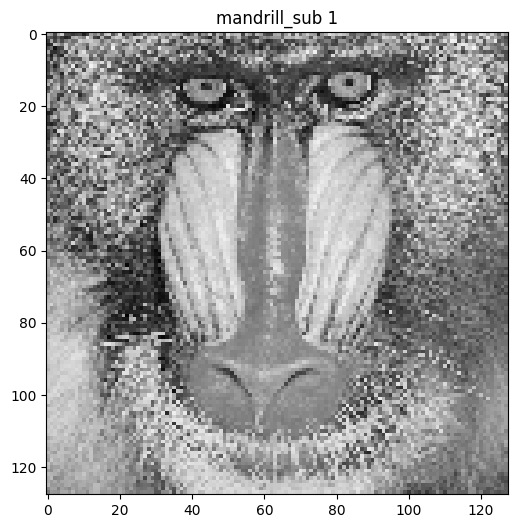

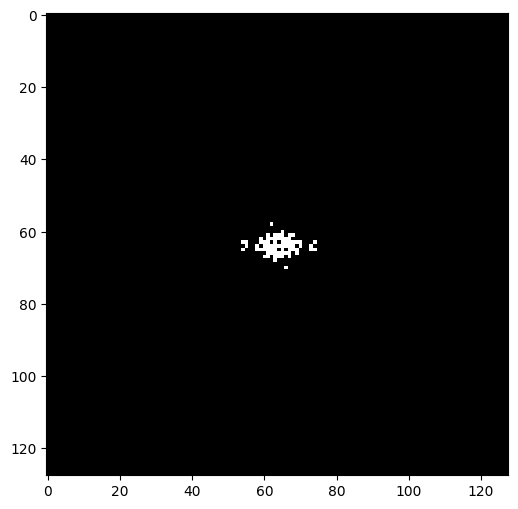

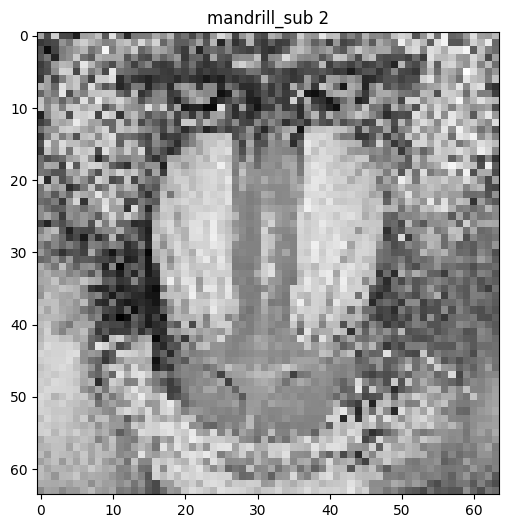

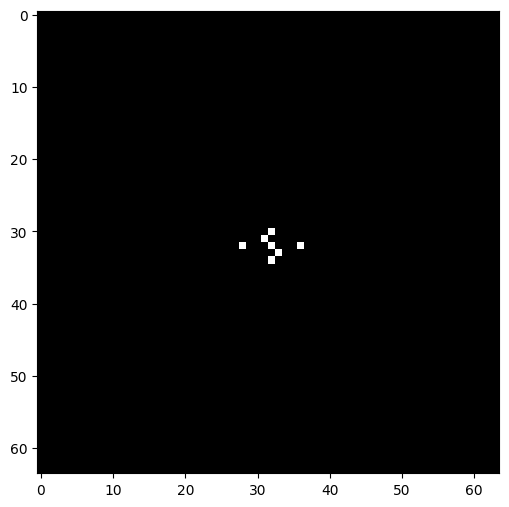

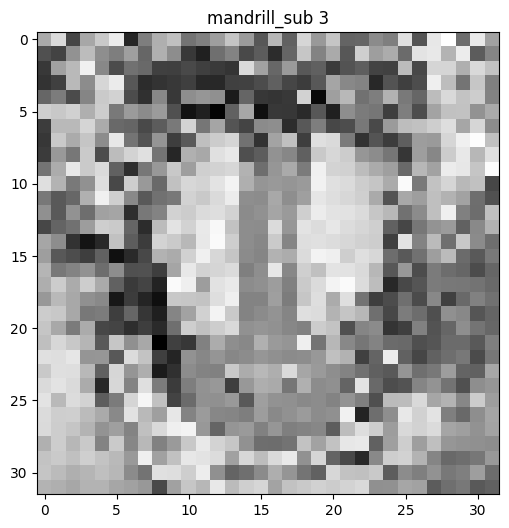

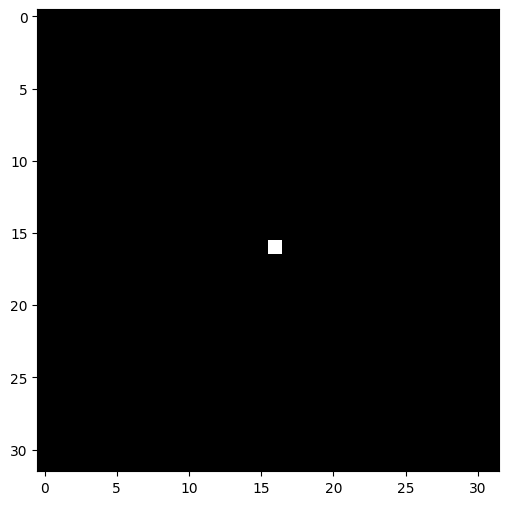

In [40]:
mandrill = np.array(Image.open('mandrill.png'))
### your code and comments start below

mandrill_aliasing = mandrill.copy()
for i in range(4):
    mandrill_aliasing = subSample2(mandrill_aliasing)
    imshow_c(mandrill_aliasing, "mandrill_sub "+str(i))
    b_fft = fft2(mandrill_aliasing)
    b_fft_cent = np.abs(fftshift(b_fft)) 
    b_fft_log = np.log(1+b_fft_cent)
    # imshow_c(b_fft_log>11.10)
    imshow_c(b_fft_log>10.10)